<a href="https://colab.research.google.com/github/Ysabellyysa/Python/blob/main/gpt_dev_Pratica_comentado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# bibliotecas
import os
import torch
import torch.nn as nn
from torch.nn import functional as F

In [2]:
with open("/content/Livros_Corpus.txt", "r", encoding="utf-8") as f:
    text = f.read()

print(f"total de caracteres: {len(text)}")
print(f"total de palavras: {len(text.split())}")

total de caracteres: 13806
total de palavras: 2170


In [3]:
# início do texto
print(text[:500])

INTRODUCTION
Reading has always been shaped by the way readers talk about books. Book clubs, classroom discussions, library
recommendations, and online reviews all help readers decide what to read next, understand difficult passages, and
connect a story to their own lives. In recent years, digital reading platforms have grown into large ecosystems
where millions of readers browse catalogs, highlight passages, and write short comments. Despite this growth,
most platforms still rely on simple tool


In [4]:
# caracteres únicos
chars = sorted(list(set(text)))
vocab_size = len(chars)
print("caracteres unicos:","".join(chars))
print("tamanho do vocabulario:", vocab_size)

caracteres unicos: 
 %'(),-.012345689:ABCDEFGHIKLMNORSTUWYabcdefghijklmnopqrstuvwxyz
tamanho do vocabulario: 65


In [5]:
# conversão caractere
stoi = { ch:i for i,ch in enumerate(chars) }
itos = { i:ch for i,ch in enumerate(chars) }
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join([itos[i] for i in l])

# teste
print(encode("Illidan"))
print(decode(encode("Illidan")))

[27, 50, 50, 47, 42, 39, 52]
Illidan


In [6]:
# texto inteiro em tensor
data = torch.tensor(encode(text), dtype=torch.long)
print(data.shape, data.dtype)
print(data[:50])

torch.Size([13806]) torch.int64
tensor([27, 31, 35, 33, 32, 22, 36, 21, 35, 27, 32, 31,  0, 33, 43, 39, 42, 47,
        52, 45,  1, 46, 39, 57,  1, 39, 50, 61, 39, 63, 57,  1, 40, 43, 43, 52,
         1, 57, 46, 39, 54, 43, 42,  1, 40, 63,  1, 58, 46, 43])


In [7]:
# 90% treino, 10% validação
n = int(0.9*len(data))
train_data = data[:n]
val_data = data[n:]
print(f"treino: {len(train_data)} tokens")
print(f" validacao: {len(val_data)} tokens")

treino: 12425 tokens
 validacao: 1381 tokens


In [8]:
# o alvo é sempre o próximo caractere
block_size = 64

x = train_data[:block_size]
y = train_data[1:block_size+1]

# mostra os 5 primeiros pares
for t in range(5):
    context = x[:t+1]
    target = y[t]
    print(f"contexto: {decode(context.tolist())!r:30s}")
    print(f"alvo:{decode([target.item()])!r}")

contexto: 'I'                           
alvo:'N'
contexto: 'IN'                          
alvo:'T'
contexto: 'INT'                         
alvo:'R'
contexto: 'INTR'                        
alvo:'O'
contexto: 'INTRO'                       
alvo:'D'


In [9]:
# hiperparâmetros
batch_size = 16      # sequências por lote
block_size = 64      # tamanho máximo do contexto
max_iters = 5000     # passos de treinamento
eval_interval = 250  # a cada quantos passos avalia
learning_rate = 1e-3
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 100     # lotes usados para estimar a perda
n_embd = 64          # dimensão dos embeddings
n_head = 4           # cabeças de atenção
n_layer = 4          # blocos transformer
dropout = 0.2

print(device)
torch.manual_seed(42)

cuda


In [10]:
# lote aleatório
def get_batch(split):
    d = train_data if split == 'train' else val_data
    ix = torch.randint(len(d) - block_size, (batch_size,))
    x = torch.stack([d[i:i+block_size] for i in ix])
    y = torch.stack([d[i+1:i+block_size+1] for i in ix])
    x, y = x.to(device), y.to(device)
    return x, y

# média da perda em treino e validação
@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

In [11]:
# média dos tokens anteriores
torch.manual_seed(1337)
B,T,C = 4,8,32
x = torch.randn(B,T,C)

xbow = torch.zeros((B,T,C))
for b in range(B):
    for t in range(T):
        xprev = x[b,:t+1]
        xbow[b,t] = xprev.mean(0)

In [12]:
# versão com multiplicação de matrizes
tril = torch.tril(torch.ones(T,T))
wei = tril / tril.sum(1, keepdim=True)
xbow2 = wei @ x
print(torch.allclose(xbow, xbow2, atol=1e-6))

True


In [13]:
# versão com softmax e máscara
tril = torch.tril(torch.ones(T,T))
wei = torch.zeros((T,T))
wei = wei.masked_fill(tril == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)
xbow3 = wei @ x
print(torch.allclose(xbow, xbow3, atol=1e-4))

True


In [14]:
# atenção com key, query e value
head_size = 16
key = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)
value = nn.Linear(C, head_size, bias=False)

k = key(x)
q = query(x)
wei = q @ k.transpose(-2,-1) * head_size**-0.5  # escala evita softmax saturado

tril = torch.tril(torch.ones(T,T))
wei = wei.masked_fill(tril == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)

v = value(x)
out = wei @ v
print(out.shape)

torch.Size([4, 8, 16])


In [15]:
# uma cabeça de auto-atenção
class Head(nn.Module):

    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B,T,C = x.shape
        k = self.key(x)
        q = self.query(x)
        wei = q @ k.transpose(-2,-1) * C**-0.5
        wei = wei.masked_fill(self.tril[:T,:T] == 0, float('-inf'))  # não olha o futuro
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)
        v = self.value(x)
        return wei @ v

In [16]:
# várias cabeças em paralelo
class MultiHeadAttention(nn.Module):

    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out

In [17]:
# rede feed-forward aplicada a cada token
class FeedForward(nn.Module):

    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),  # GELU no lugar do ReLU da aula
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

In [18]:
# bloco transformer: atenção + feed-forward
class Block(nn.Module):

    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))    # conexão residual
        x = x + self.ffwd(self.ln2(x))  # conexão residual
        return x

In [19]:
# modelo de linguagem treinado no corpus de WoW
class WoWLanguageModel(nn.Module):

    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.positional_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head=n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B,T = idx.shape
        tok_emb = self.token_embedding_table(idx)
        pos_emb = self.positional_embedding_table(torch.arange(T, device=device))
        x = tok_emb + pos_emb  # token + posição
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)

        if targets is None:
            loss = None
        else:
            B,T,C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens, temperature=1.0):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]  # mantém só o contexto máximo
            logits, loss = self(idx_cond)
            logits = logits[:, -1, :] / temperature  # temperature controla a criatividade
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

model = WoWLanguageModel()
m = model.to(device)
print(f"parametros:{sum(p.numel() for p in model.parameters()):,}")

parametros:211,777


In [20]:
# baseline: geração antes do treino
context = torch.zeros((1, 1), dtype=torch.long, device=device)
print(decode(m.generate(context, max_new_tokens=200, temperature=1.0)[0].tolist()))


FvHeLT2DaLekNFTvHaaDA2gc9%KsYoc::(oRhqzeLFDIu92Tggjrhhqq29s
d%wF(Yq-(ygww)Kq'nnB-yU.esu
hhnqRzyymtnHS6-%CeLiqn-N9u8t0qwt5jx'nWy-wnm8Rnylbd ue tD Mnqasbngej89Wy61 )scf1hli9bahiol'-wyy AEt:w
FGnDd3-U3(8


In [21]:
# treinamento
import matplotlib.pyplot as plt

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
train_losses = []
val_losses = []

for iter in range(max_iters):

    if iter % eval_interval == 0 or iter == max_iters - 1:
        losses = estimate_loss()
        train_losses.append(losses['train'].item())
        val_losses.append(losses['val'].item())
        print(f"step {iter}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")

    xb, yb = get_batch('train')

    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

step 0: train loss 4.3043, val loss 4.3015
step 250: train loss 2.4013, val loss 2.4369
step 500: train loss 2.2502, val loss 2.3192
step 750: train loss 2.0142, val loss 2.0960
step 1000: train loss 1.7736, val loss 1.9065
step 1250: train loss 1.5888, val loss 1.8007
step 1500: train loss 1.4194, val loss 1.7032
step 1750: train loss 1.2839, val loss 1.6761
step 2000: train loss 1.1727, val loss 1.6441
step 2250: train loss 1.0855, val loss 1.6191
step 2500: train loss 0.9916, val loss 1.6083
step 2750: train loss 0.9152, val loss 1.6203
step 3000: train loss 0.8519, val loss 1.6617
step 3250: train loss 0.7968, val loss 1.6908
step 3500: train loss 0.7480, val loss 1.6727
step 3750: train loss 0.7023, val loss 1.6925
step 4000: train loss 0.6574, val loss 1.7266
step 4250: train loss 0.6223, val loss 1.7220
step 4500: train loss 0.5811, val loss 1.7737
step 4750: train loss 0.5662, val loss 1.7873
step 4999: train loss 0.5289, val loss 1.7989


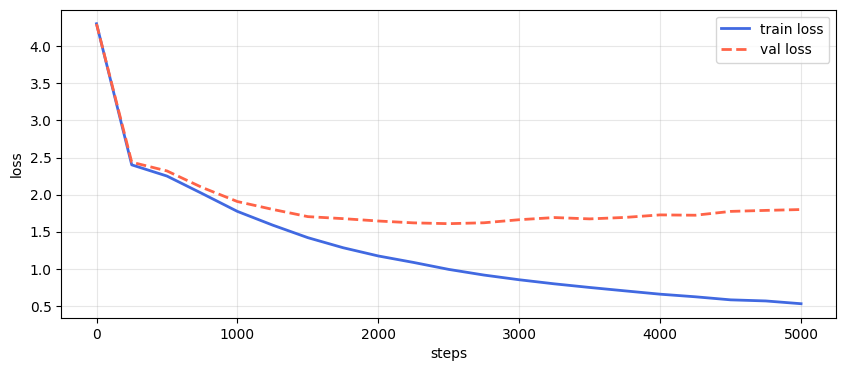

In [22]:
# curva de aprendizado
steps = list(range(0, max_iters+1, eval_interval))[:len(train_losses)]

plt.figure(figsize=(10,4))
plt.plot(steps, train_losses, label='train loss', color='royalblue', linewidth=2)
plt.plot(steps, val_losses, label='val loss', color='tomato', linewidth=2, linestyle='--')
plt.xlabel('steps')
plt.ylabel('loss')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [23]:
# melhor ponto da validação
best = min(range(len(val_losses)), key=lambda i: val_losses[i])
print(f"melhor val loss: {val_losses[best]:.4f} no step {steps[best]}")
print(f"val loss final: {val_losses[-1]:.4f}")

melhor val loss: 1.6083 no step 2500
val loss final: 1.7989


In [24]:
# compara 3 temperaturas
for temp in [0.7, 1.0, 1.5]:
    print(f"temperature = {temp}")
    ctx = torch.zeros((1, 1), dtype=torch.long, device=device)
    print(decode(m.generate(ctx, max_new_tokens=300, temperature=temp)[0].tolist()))

temperature = 0.7

the adjusting and of literary and discussions style fine time-t of training a rover helply dupussen about it alway
tone small answers too shame model veer feques and the model sen stypes time of literarnations
because a book bethey lighlight
was find a for a novew the study a corpussed was reading g
temperature = 1.0

lver gatpeational brarely itle wrong charapter. Serious was to evends show by sthowed that much as stayet of lists passed
the mat reading nurarare commonces of booke with to morize on systemble that used the basecves. Networked the behave most to
muncendation book lange
vel exaw.
herre meaning hougg
temperature = 1.5

onmest wevatigate quality dipesp drommenation, sture, unvied aftervention which the rainis kerections, and nity scosiof was reasonsed evendylitth a noteedainal reading charactuall of bary, of discunerstions. Dut ouillic passing tyesics pans
questions, for or
eveairy helst, Lang croscenby, frose tool


In [25]:
# geração a partir de um texto inicial
prompt = "The model"
ctx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
print(decode(m.generate(ctx, max_new_tokens=300, temperature=0.7)[0].tolist()))

The models of produlding and the remay reader explations for pubs.ese thraining guides Such model tools sen specifictions often litery tools case somportalned the model. An models prop was after study followsts all wry are mover for begenumments was adve the lowed naped took cand chapter tools of several gan
